<a href="https://colab.research.google.com/github/faisal2302/DataScience_DataPreprocessing/blob/main/Tugas_Data_Preprocessing_Nasabah.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Data Science – Data Preprocessing

**Studi kasus:** Persiapan data nasabah untuk analisis potensi gagal bayar (Status_Default).

Notebook ini menjalankan tahapan A–G sesuai instruksi tugas. Jalankan sel secara berurutan. File nasabah_raw.csv dan data_kredit_eksternal.csv

## 1. Import Library dan Membaca Dataset

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Jika menggunakan Google Colab, unggah kedua file CSV terlebih dahulu.
df = pd.read_csv('nasabah_raw.csv')
data_eksternal = pd.read_csv('data_kredit_eksternal.csv')

print("Dataset utama:", df.shape)
print("Dataset eksternal:", data_eksternal.shape)

Dataset utama: (1045, 9)
Dataset eksternal: (850, 3)


## A. Pemeriksaan Awal dan Penghapusan Duplikat

In [13]:
# Dimensi dan informasi tipe data
print("Dimensi awal:", df.shape)
display(df.info())

# Menghitung dan menampilkan sampel baris duplikat penuh
jumlah_duplikat = df.duplicated().sum()
print("Jumlah duplikat penuh:", jumlah_duplikat)
display(df[df.duplicated(keep=False)].head(10))

# Menghapus seluruh duplikat penuh
df = df.drop_duplicates().copy()
print("Dimensi setelah menghapus duplikat:", df.shape)

Dimensi awal: (1045, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1045 entries, 0 to 1044
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID_Pelanggan            1045 non-null   object 
 1   Usia                    1045 non-null   float64
 2   Pendapatan_Bulanan      983 non-null    float64
 3   Skor_Kredit             1045 non-null   float64
 4   Lama_Bekerja_Thn        1003 non-null   float64
 5   Status_Pernikahan       1045 non-null   object 
 6   Tingkat_Pendidikan      1008 non-null   object 
 7   Status_Default          1045 non-null   int64  
 8   Pendapatan_Tahunan_Est  983 non-null    float64
dtypes: float64(5), int64(1), object(3)
memory usage: 73.6+ KB


None

Jumlah duplikat penuh: 45


,ID_Pelanggan,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Status_Pernikahan,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est
59,CUST-1060,53.0,14765000.0,461.0,3.0,Single,SMA,0,177180000.0
76,CUST-1077,34.0,6920000.0,510.0,22.0,Single,SMA,1,83040000.0
96,CUST-1097,27.0,12499000.0,578.0,4.0,Single,Sarjana,0,149988000.0
101,CUST-1102,43.0,7972000.0,365.0,6.0,Single,Magister,1,95664000.0
136,CUST-1137,-5.0,NaN,580.0,11.0,Cerai,Sarjana,1,NaN
139,CUST-1140,47.0,13297000.0,453.0,8.0,Menikah,SMA,0,159564000.0
174,CUST-1175,21.0,12310000.0,768.0,1.0,MENIKAH,SMA,0,147720000.0
198,CUST-1199,52.0,15690000.0,849.0,11.0,Menikah,Magister,0,188280000.0
210,CUST-1211,39.0,7184000.0,646.0,NaN,Single,SMA,0,86208000.0
235,CUST-1236,28.0,10489000.0,681.0,20.0,Cerai,Sarjana,0,125868000.0


Dimensi setelah menghapus duplikat: (1000, 9)


**Analisis:** Dataset utama awal memiliki 1,045 baris dan 9 kolom. Ditemukan 45 baris duplikat penuh. Setelah penghapusan, tersisa 1,000 baris. Penghapusan duplikat mencegah catatan yang sama dihitung berulang dalam analisis.

## B. Penanganan Kesalahan Data

In [14]:
# Periksa kategori sebelum dibersihkan
print("Kategori Status_Pernikahan sebelum dibersihkan:")
print(df['Status_Pernikahan'].value_counts(dropna=False))

# Hilangkan spasi di awal/akhir dan samakan kapitalisasi
df['Status_Pernikahan'] = (
    df['Status_Pernikahan'].astype('string').str.strip().str.title()
)
print("\nKategori setelah dibersihkan:")
print(df['Status_Pernikahan'].value_counts(dropna=False))

# Validasi usia: usia di luar 17–100 dianggap tidak wajar dan dijadikan NaN
kondisi_usia_tidak_valid = (df['Usia'] < 17) | (df['Usia'] > 100)
print("\nJumlah usia tidak valid:", kondisi_usia_tidak_valid.sum())
df.loc[kondisi_usia_tidak_valid, 'Usia'] = np.nan
print("Jumlah missing pada Usia setelah validasi:", df['Usia'].isna().sum())

Kategori Status_Pernikahan sebelum dibersihkan:
Status_Pernikahan
Menikah      509
Single       342
Cerai         82
single        37
 MENIKAH      30
Name: count, dtype: int64

Kategori setelah dibersihkan:
Status_Pernikahan
Menikah    539
Single     379
Cerai       82
Name: count, dtype: Int64

Jumlah usia tidak valid: 35
Jumlah missing pada Usia setelah validasi: 35


**Analisis:** Nilai kategori seperti single, Single, dan MENIKAH perlu diseragamkan agar tidak dianggap sebagai kategori berbeda. Batas usia 17–100 tahun digunakan sesuai contoh pada instruksi. Pada data ini ditemukan 35 nilai usia tidak valid. Nilai tersebut diubah menjadi NaN agar tidak memengaruhi perhitungan median. Jika nilai tidak wajar dibiarkan, ukuran pemusatan seperti mean/median dapat menjadi tidak representatif.

## C. Integrasi Data

In [15]:
# Left join menjaga seluruh baris dari dataset utama
df_gabungan = pd.merge(
    df,
    data_eksternal,
    on='ID_Pelanggan',
    how='left'
)
print("Dimensi setelah left join:", df_gabungan.shape)
display(df_gabungan.head())

Dimensi setelah left join: (1000, 11)


,ID_Pelanggan,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Status_Pernikahan,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est,Pernah_Gagal_Bayar_Lain,Jumlah_Kartu_Kredit
0,CUST-1001,58.0,10118000.0,542.0,13.0,Menikah,Magister,0,121416000.0,Tidak,5.0
1,CUST-1002,48.0,10514000.0,331.0,20.0,Menikah,Sarjana,0,126168000.0,Tidak,3.0
2,CUST-1003,34.0,13257000.0,690.0,22.0,Menikah,Magister,0,159084000.0,Tidak,5.0
3,CUST-1004,27.0,10832000.0,576.0,7.0,Menikah,Sarjana,0,129984000.0,Ya,6.0
4,CUST-1005,NaN,8295000.0,831.0,15.0,Single,SMA,0,99540000.0,Ya,4.0


**Analisis:** Penggabungan dilakukan berdasarkan ID_Pelanggan dengan how='left'. Dengan demikian, seluruh nasabah pada dataset utama tetap dipertahankan. Dataset gabungan memiliki 1,000 baris dan 11 kolom. Nasabah yang tidak memiliki pasangan pada data eksternal akan memiliki nilai kosong pada kolom tambahan.

## D. Penanganan Missing Values

In [16]:
# Persentase missing value sebelum imputasi
persentase_missing = (df_gabungan.isna().mean() * 100).sort_values(ascending=False)
display(persentase_missing.to_frame('Persentase Missing (%)'))

# Kolom numerik kontinu: imputasi median
kolom_median = [
    'Usia',
    'Pendapatan_Bulanan',
    'Lama_Bekerja_Thn',
    'Pendapatan_Tahunan_Est'
]
for kolom in kolom_median:
    df_gabungan[kolom] = df_gabungan[kolom].fillna(df_gabungan[kolom].median())

# Jumlah kartu kredit yang kosong diasumsikan 0
df_gabungan['Jumlah_Kartu_Kredit'] = df_gabungan['Jumlah_Kartu_Kredit'].fillna(0)

# Kolom kategorikal: imputasi modus
kolom_modus = ['Tingkat_Pendidikan', 'Pernah_Gagal_Bayar_Lain']
for kolom in kolom_modus:
    nilai_modus = df_gabungan[kolom].mode(dropna=True)
    nilai_pengisi = nilai_modus.iloc[0] if not nilai_modus.empty else 'Tidak Diketahui'
    df_gabungan[kolom] = df_gabungan[kolom].fillna(nilai_pengisi)

print("Total missing value setelah imputasi:", df_gabungan.isna().sum().sum())
display(df_gabungan.isna().sum().to_frame('Jumlah Missing'))

,Persentase Missing (%)
Pernah_Gagal_Bayar_Lain,15.0
Jumlah_Kartu_Kredit,15.0
Pendapatan_Bulanan,6.0
Pendapatan_Tahunan_Est,6.0
Lama_Bekerja_Thn,4.0
Tingkat_Pendidikan,3.5
Usia,3.5
ID_Pelanggan,0.0
Skor_Kredit,0.0
Status_Pernikahan,0.0


Total missing value setelah imputasi: 0


,Jumlah Missing
ID_Pelanggan,0
Usia,0
Pendapatan_Bulanan,0
Skor_Kredit,0
Lama_Bekerja_Thn,0
Status_Pernikahan,0
Tingkat_Pendidikan,0
Status_Default,0
Pendapatan_Tahunan_Est,0
Pernah_Gagal_Bayar_Lain,0


**Analisis:** Kolom numerik kontinu diisi dengan median karena median lebih tahan terhadap nilai ekstrem dibandingkan mean. Jumlah_Kartu_Kredit diisi 0 mengikuti asumsi instruksi. Kolom kategorikal diisi dengan modus. Pendapatan_Tahunan_Est juga diimputasi median karena merupakan kolom numerik yang memiliki nilai kosong pada dataset. Setelah imputasi, seluruh missing value harus bernilai 0.

## E. Penanganan Pencilan (Outlier Handling)

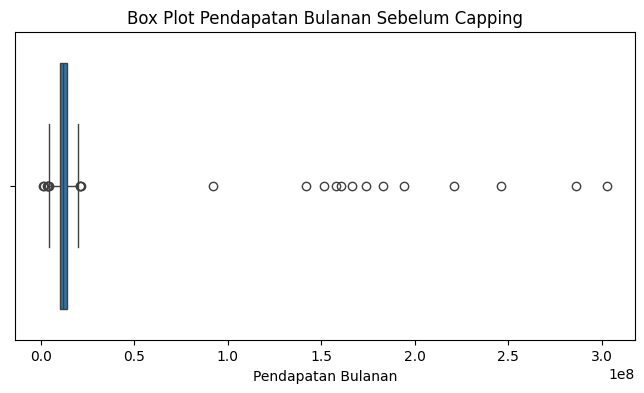

Q1: 10192000.0
Q3: 14100250.0
IQR: 3908250.0
Batas bawah: 4329625.0
Batas atas: 19962625.0
Jumlah outlier: 22


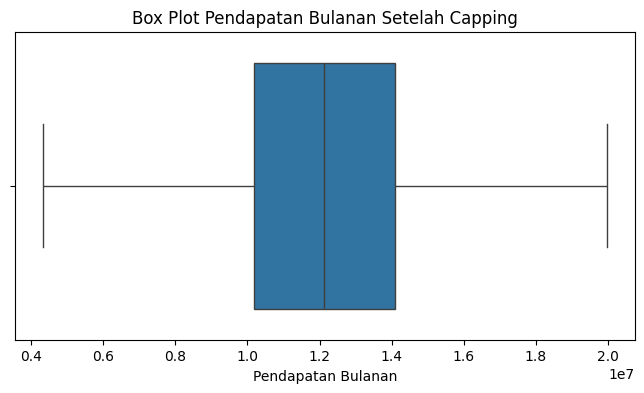

In [17]:
# Box plot sebelum pembatasan outlier
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_gabungan['Pendapatan_Bulanan'])
plt.title('Box Plot Pendapatan Bulanan Sebelum Capping')
plt.xlabel('Pendapatan Bulanan')
plt.show()

# Menghitung batas bawah dan batas atas dengan IQR
Q1 = df_gabungan['Pendapatan_Bulanan'].quantile(0.25)
Q3 = df_gabungan['Pendapatan_Bulanan'].quantile(0.75)
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Batas bawah:", batas_bawah)
print("Batas atas:", batas_atas)

jumlah_outlier = (
    (df_gabungan['Pendapatan_Bulanan'] < batas_bawah) |
    (df_gabungan['Pendapatan_Bulanan'] > batas_atas)
).sum()
print("Jumlah outlier:", jumlah_outlier)

# Capping: nilai di luar batas diganti dengan nilai batas terdekat
df_gabungan['Pendapatan_Bulanan'] = df_gabungan['Pendapatan_Bulanan'].clip(
    lower=batas_bawah,
    upper=batas_atas
)

# Box plot setelah pembatasan
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_gabungan['Pendapatan_Bulanan'])
plt.title('Box Plot Pendapatan Bulanan Setelah Capping')
plt.xlabel('Pendapatan Bulanan')
plt.show()

**Analisis:** Metode IQR digunakan untuk menentukan batas nilai wajar pendapatan bulanan. Nilai di luar batas tidak dihapus, tetapi dibatasi (*capping*) ke batas bawah atau atas. Cara ini mempertahankan jumlah nasabah. Jika baris outlier dihapus, jumlah dan keragaman data berkurang serta informasi nasabah berpendapatan sangat rendah/tinggi dapat hilang.

## F. Pengkodean Data Kategorikal

In [18]:
# Ordinal encoding: pendidikan memiliki urutan tingkat
peta_pendidikan = {'SMA': 1, 'Sarjana': 2, 'Magister': 3}
df_gabungan['Tingkat_Pendidikan'] = df_gabungan['Tingkat_Pendidikan'].map(peta_pendidikan)

# Binary mapping
peta_gagal_bayar = {'Tidak': 0, 'Ya': 1}
df_gabungan['Pernah_Gagal_Bayar_Lain'] = (
    df_gabungan['Pernah_Gagal_Bayar_Lain']
    .astype('string').str.strip().str.title()
    .map(peta_gagal_bayar)
)

# One-Hot Encoding; drop_first=True menghindari satu dummy berlebih
df_gabungan = pd.get_dummies(
    df_gabungan,
    columns=['Status_Pernikahan'],
    drop_first=True,
    dtype=int
)

# Hapus identifier karena tidak menjadi fitur prediktif
df_gabungan = df_gabungan.drop(columns=['ID_Pelanggan'])

display(df_gabungan.head())
print("Kolom setelah encoding:", df_gabungan.columns.tolist())

,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est,Pernah_Gagal_Bayar_Lain,Jumlah_Kartu_Kredit,Status_Pernikahan_Menikah,Status_Pernikahan_Single
0,58.0,10118000.0,542.0,13.0,3,0,121416000.0,0,5.0,1,0
1,48.0,10514000.0,331.0,20.0,2,0,126168000.0,0,3.0,1,0
2,34.0,13257000.0,690.0,22.0,3,0,159084000.0,0,5.0,1,0
3,27.0,10832000.0,576.0,7.0,2,0,129984000.0,1,6.0,1,0
4,41.0,8295000.0,831.0,15.0,1,0,99540000.0,1,4.0,0,1


Kolom setelah encoding: ['Usia', 'Pendapatan_Bulanan', 'Skor_Kredit', 'Lama_Bekerja_Thn', 'Tingkat_Pendidikan', 'Status_Default', 'Pendapatan_Tahunan_Est', 'Pernah_Gagal_Bayar_Lain', 'Jumlah_Kartu_Kredit', 'Status_Pernikahan_Menikah', 'Status_Pernikahan_Single']


**Analisis:** Tingkat_Pendidikan dikodekan secara ordinal sesuai urutan SMA (1), Sarjana (2), dan Magister (3). Pernah_Gagal_Bayar_Lain diubah menjadi 0 dan 1. Status_Pernikahan diubah menjadi kolom dummy dengan drop_first=True. Kolom ID dihapus karena hanya berfungsi sebagai identitas, bukan informasi karakteristik untuk prediksi.

## G. Penskalaan Fitur (Feature Scaling)

In [19]:
# Pisahkan fitur prediktor (X) dan target (y)
y = df_gabungan['Status_Default'].copy()
X = df_gabungan.drop(columns=['Status_Default']).copy()

# Simpan ringkasan statistik sebelum scaling untuk 3 fitur numerik
tiga_fitur = ['Usia', 'Pendapatan_Bulanan', 'Skor_Kredit']
print("Statistik sebelum standardisasi:")
display(X[tiga_fitur].describe())

# Standardisasi seluruh fitur numerik prediktor dengan Z-score
fitur_numerik = X.select_dtypes(include=np.number).columns
scaler = StandardScaler()
X_scaled = X.copy()
X_scaled[fitur_numerik] = scaler.fit_transform(X[fitur_numerik])

print("Statistik sesudah standardisasi:")
display(X_scaled[tiga_fitur].describe())

# Gabungkan kembali fitur dan target (target tidak distandardisasi)
data_final = X_scaled.copy()
data_final['Status_Default'] = y

print("Dimensi data final:", data_final.shape)
print("Total missing value:", data_final.isna().sum().sum())

Statistik sebelum standardisasi:


,Usia,Pendapatan_Bulanan,Skor_Kredit
count,1000.000000,1.000000e+03,1000.000000
mean,40.082000,1.212750e+07,580.507000
std,11.580128,3.062611e+06,158.990729
min,20.000000,4.329625e+06,300.000000
25%,30.000000,1.019200e+07,440.750000
50%,41.000000,1.213200e+07,579.000000
75%,50.000000,1.410025e+07,722.250000
max,59.000000,1.996262e+07,849.000000


Statistik sesudah standardisasi:


,Usia,Pendapatan_Bulanan,Skor_Kredit
count,1.000000e+03,1.000000e+03,1.000000e+03
mean,-7.105427e-17,3.552714e-18,3.232969e-16
std,1.000500e+00,1.000500e+00,1.000500e+00
min,-1.735045e+00,-2.547425e+00,-1.765181e+00
25%,-8.710650e-01,-6.322922e-01,-8.794659e-01
50%,7.931340e-02,1.471131e-03,-9.483283e-03
75%,8.568957e-01,6.444632e-01,8.919635e-01
max,1.634478e+00,2.559596e+00,1.689579e+00


Dimensi data final: (1000, 11)
Total missing value: 0


**Analisis:** Standardisasi Z-score mengubah fitur numerik prediktor agar memiliki rata-rata mendekati 0 dan standar deviasi mendekati 1. Target Status_Default tidak ikut distandardisasi karena merupakan label yang akan diprediksi. One-hot hasil encoding juga tidak perlu diskalakan sebagai fitur numerik kontinu; pada implementasi ini StandardScaler diterapkan ke seluruh kolom numerik X, termasuk kolom hasil encoding, sesuai instruksi 'seluruh variabel numerik'.

## 10. Menyimpan Dataset Final

In [20]:
# Simpan hasil preprocessing
data_final.to_csv('clean_nasabah_final.csv', index=False)
print("File berhasil disimpan: clean_nasabah_final.csv")
display(data_final.head())

File berhasil disimpan: clean_nasabah_final.csv


,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Tingkat_Pendidikan,Pendapatan_Tahunan_Est,Pernah_Gagal_Bayar_Lain,Jumlah_Kartu_Kredit,Status_Pernikahan_Menikah,Status_Pernikahan_Single,Status_Default
0,1.548080,-0.656467,-0.242318,0.007777,1.591395,-0.196932,-0.367524,1.204949,0.924818,-0.781221,0
1,0.684100,-0.527101,-1.570103,1.054639,0.148607,-0.178474,-0.367524,0.255423,0.924818,-0.781221,0
2,-0.525473,0.368989,0.689020,1.353742,1.591395,-0.050615,-0.367524,1.204949,0.924818,-0.781221,0
3,-1.130259,-0.423216,-0.028362,-0.889534,0.148607,-0.163651,2.720912,1.679712,0.924818,-0.781221,0
4,0.079313,-1.252008,1.576308,0.306880,-1.294181,-0.281907,2.720912,0.730186,-1.081294,1.280048,0
